In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        print(os.path.join(root, file))

/kaggle/input/datasets/divyasririthaa/heart-disease-analysis-dataset/processed_cleveland_data.csv
/kaggle/input/notebooks/mragpavank/heart-disease-uci/__results__.html
/kaggle/input/notebooks/mragpavank/heart-disease-uci/__resultx__.html
/kaggle/input/notebooks/mragpavank/heart-disease-uci/__notebook__.ipynb
/kaggle/input/notebooks/mragpavank/heart-disease-uci/__output__.json
/kaggle/input/notebooks/mragpavank/heart-disease-uci/custom.css


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
columns = [
    "age", "sex", "cp", "trestbps", "chol",
    "fbs", "restecg", "thalach", "exang",
    "oldpeak", "slope", "ca", "thal", "target"
]

file_path = "/kaggle/input/datasets/divyasririthaa/heart-disease-analysis-dataset/processed_cleveland_data.csv"

df = pd.read_csv(
    file_path,
    header=None,
    names=columns,
    na_values="?"
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Dataset shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
index,63,1,1.1,145,233,1.2,2,150,0,2.3,3,0.1,6.0,0.2
0,67,1,4.0,160,286,0.0,2,108,1,1.5,2,3.0,3.0,2.0
1,67,1,4.0,120,229,0.0,2,129,1,2.6,2,2.0,7.0,1.0
2,37,1,3.0,130,250,0.0,0,187,0,3.5,3,0.0,3.0,0.0
3,41,0,2.0,130,204,0.0,2,172,0,1.4,1,0.0,3.0,0.0


In [4]:
print("Dataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
Index: 303 entries, index to 301
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  target    303 non-null    float64
dtypes: float64(6), int64(8)
memory usage: 35.5+ KB

Statistical Summary:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,299.000000,301.000000,303.000000
mean,54.438944,0.679868,3.158746,131.689769,246.693069,0.149175,0.990099,149.607261,0.326733,1.039604,1.600660,0.672575,4.734219,0.937954
std,9.038662,0.467299,0.959398,17.599748,51.776918,0.357962,0.994971,22.875003,0.469794,1.161075,0.616226,0.937215,1.939706,1.228084
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000,2.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.200000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000,4.000000



Missing Values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64


In [5]:
df = df.drop_duplicates().copy()

for col in df.columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("Missing values after conversion:")
print(df.isnull().sum())

print("\nCleaned dataset shape:", df.shape)

Missing values after conversion:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64

Cleaned dataset shape: (303, 14)


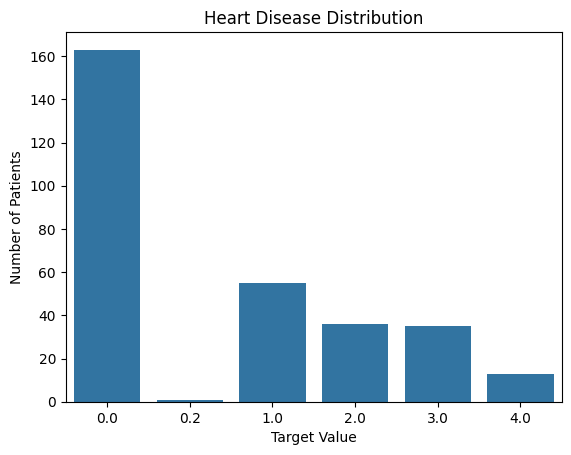

In [6]:
sns.countplot(data=df, x="target")
plt.title("Heart Disease Distribution")
plt.xlabel("Target Value")
plt.ylabel("Number of Patients")
plt.show()

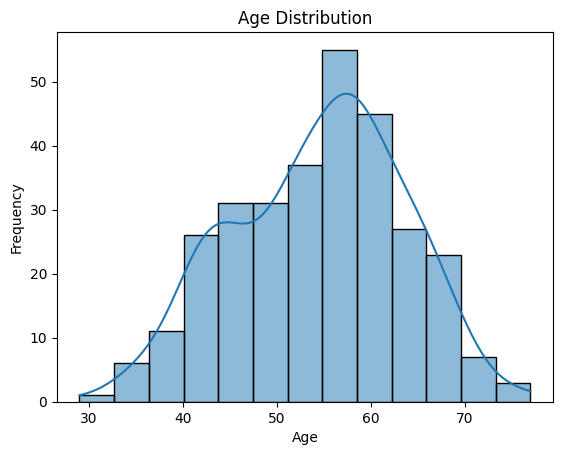

In [7]:
sns.histplot(data=df, x="age", kde=True)
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()

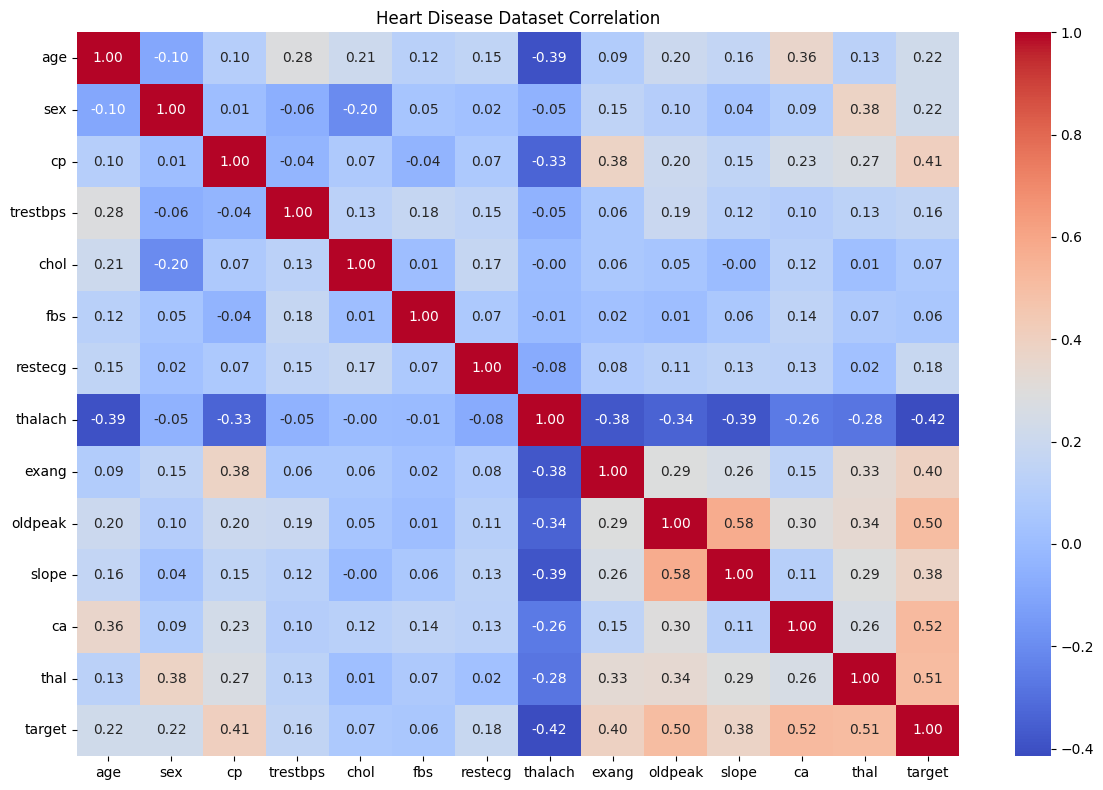

In [8]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Heart Disease Dataset Correlation")
plt.tight_layout()
plt.show()

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

file_path = "/kaggle/input/datasets/divyasririthaa/heart-disease-analysis-dataset/processed_cleveland_data.csv"

df = pd.read_csv(file_path)

print("Dataset Shape:", df.shape)
print("\nFirst 5 Rows:")
display(df.head())

print("\nColumn Names:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (302, 15)

First 5 Rows:


,index,63,1,1.1,145,233,1.2,2,150,0,2.3,3,0.1,6,0.2
0,0,67,1,4,160,286,0,2,108,1,1.5,2,3,3,2
1,1,67,1,4,120,229,0,2,129,1,2.6,2,2,7,1
2,2,37,1,3,130,250,0,0,187,0,3.5,3,0,3,0
3,3,41,0,2,130,204,0,2,172,0,1.4,1,0,3,0
4,4,56,1,2,120,236,0,0,178,0,0.8,1,0,3,0



Column Names:
['index', '63', '1', '1.1', '145', '233', '1.2', '2', '150', '0', '2.3', '3', '0.1', '6', '0.2']

Missing Values:
index    0
63       0
1        0
1.1      0
145      0
233      0
1.2      0
2        0
150      0
0        0
2.3      0
3        0
0.1      0
6        0
0.2      0
dtype: int64


In [10]:
# Replace missing-value symbols with NaN
df = df.replace("?", np.nan)

# Convert columns to numeric values
for col in df.columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("Missing Values Before Cleaning:")
print(df.isnull().sum())

# Remove duplicate rows
df = df.drop_duplicates()

# Fill missing values using column median
df = df.fillna(df.median(numeric_only=True))

print("\nDataset Shape After Cleaning:", df.shape)
print("\nMissing Values After Cleaning:")
print(df.isnull().sum())

Missing Values Before Cleaning:
index    0
63       0
1        0
1.1      0
145      0
233      0
1.2      0
2        0
150      0
0        0
2.3      0
3        0
0.1      4
6        2
0.2      0
dtype: int64

Dataset Shape After Cleaning: (302, 15)

Missing Values After Cleaning:
index    0
63       0
1        0
1.1      0
145      0
233      0
1.2      0
2        0
150      0
0        0
2.3      0
3        0
0.1      0
6        0
0.2      0
dtype: int64


In [11]:
# 1. Heart disease distribution
print("Target Value Counts:")
print(df["target"].value_counts().sort_index())

df["target"].value_counts().sort_index().plot(kind="bar")
plt.title("Heart Disease Distribution")
plt.xlabel("Target Class")
plt.ylabel("Number of People")
plt.tight_layout()
plt.show()

# 2. Age distribution
df["age"].hist(bins=15)
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of People")
plt.tight_layout()
plt.show()

# 3. Correlation heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Heart Disease Dataset Correlation")
plt.tight_layout()
plt.show()

# 4. Average values by target class
display(df.groupby("target").mean(numeric_only=True).round(2))

Target Value Counts:


KeyError: 'target'

In [12]:

print(df.columns.tolist())


['index', '63', '1', '1.1', '145', '233', '1.2', '2', '150', '0', '2.3', '3', '0.1', '6', '0.2']


In [13]:
df = pd.read_csv(
    "/kaggle/input/datasets/divyasririthaa/heart-disease-analysis-dataset/processed_cleveland_data.csv",
    header=None
)

df.columns = [
    "age", "sex", "cp", "trestbps", "chol", "fbs",
    "restecg", "thalach", "exang", "oldpeak", "slope",
    "ca", "thal", "target", "extra"
]

print(df.head())
print(df.shape)

     age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  \
0  index   63   1       1.1   145  233      1.2        2    150        0   
1      0   67   1       4.0   160  286      0.0        2    108        1   
2      1   67   1       4.0   120  229      0.0        2    129        1   
3      2   37   1       3.0   130  250      0.0        0    187        0   
4      3   41   0       2.0   130  204      0.0        2    172        0   

   slope  ca thal target  extra  
0    2.3   3  0.1      6    0.2  
1    1.5   2    3      3    2.0  
2    2.6   2    2      7    1.0  
3    3.5   3    0      3    0.0  
4    1.4   1    0      3    0.0  
(303, 15)


In [14]:
# Remove the unwanted first column and extra column
df = df.drop(columns=["extra"])
df = df.iloc[1:].reset_index(drop=True)

# Convert all columns to numeric
for col in df.columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Check dataset
print("Dataset Shape:", df.shape)
print("Columns:", df.columns.tolist())
print(df.head())

Dataset Shape: (302, 14)
Columns: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']
   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0    0   67   1       4.0   160  286      0.0        2    108        1    1.5   
1    1   67   1       4.0   120  229      0.0        2    129        1    2.6   
2    2   37   1       3.0   130  250      0.0        0    187        0    3.5   
3    3   41   0       2.0   130  204      0.0        2    172        0    1.4   
4    4   56   1       2.0   120  236      0.0        0    178        0    0.8   

   ca  thal  target  
0   2   3.0     3.0  
1   2   2.0     7.0  
2   3   0.0     3.0  
3   1   0.0     3.0  
4   1   0.0     3.0  


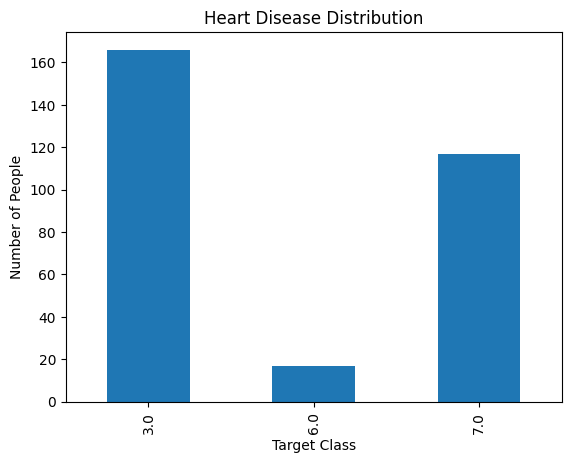

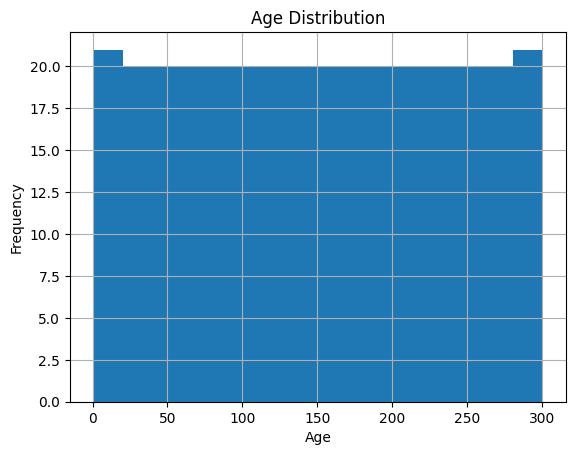

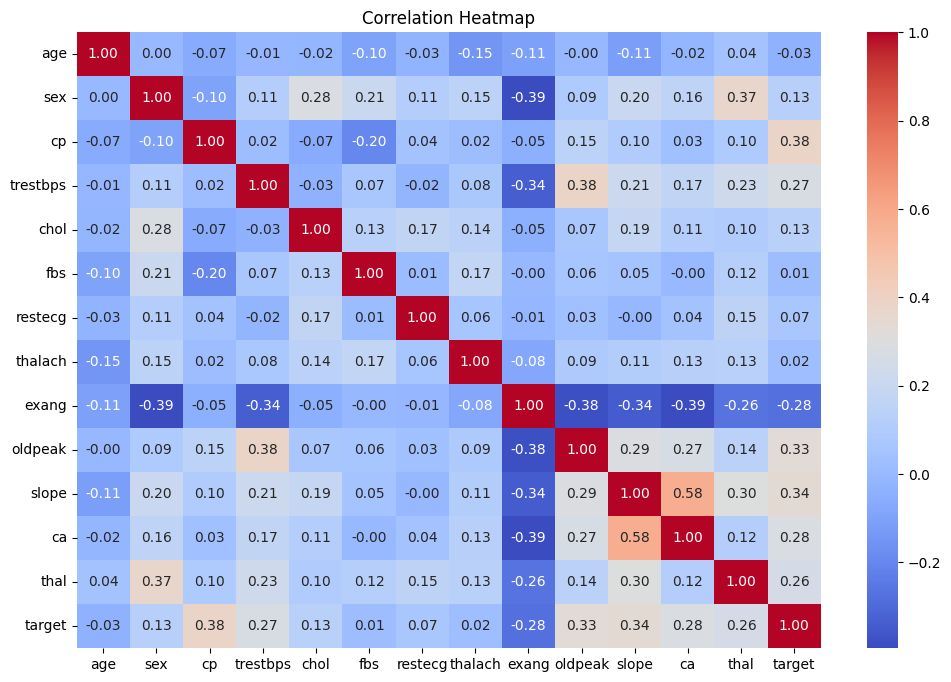

In [15]:
# Heart disease distribution
df["target"].value_counts().sort_index().plot(kind="bar")
plt.title("Heart Disease Distribution")
plt.xlabel("Target Class")
plt.ylabel("Number of People")
plt.show()

# Age distribution
df["age"].hist(bins=15)
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()

# Correlation heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

In [16]:

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

# Convert target into two classes
# 0 = No heart disease, 1 = Heart disease
data = df.copy()
data["target"] = (data["target"] > 0).astype(int)

# Separate features and target
X = data.drop(columns=["target"])
y = data["target"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Create and train model
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)
model.fit(X_train, y_train)

# Predict and evaluate
y_pred = model.predict(X_test)

print("Model Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

# Display confusion matrix
ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.title("Heart Disease Prediction - Confusion Matrix")
plt.tight_layout()
plt.show()


ValueError: Input X contains NaN.
LogisticRegression does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values

In [17]:

# Fill missing values and prepare the dataset
data = df.copy()

data = data.replace("?", np.nan)

for col in data.columns:
    data[col] = pd.to_numeric(data[col], errors="coerce")

# Remove rows where target is missing
data = data.dropna(subset=["target"]).copy()

# Fill missing feature values using median
feature_cols = [col for col in data.columns if col != "target"]
data[feature_cols] = data[feature_cols].fillna(
    data[feature_cols].median()
)

# Convert target into two classes
data["target"] = (data["target"] > 0).astype(int)

print("Missing values remaining:", data.isnull().sum().sum())
print("Dataset shape:", data.shape)


Missing values remaining: 0
Dataset shape: (300, 14)


In [18]:

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

X = data.drop(columns=["target"])
y = data["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Model Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.title("Heart Disease Prediction - Confusion Matrix")
plt.tight_layout()
plt.show()


ValueError: This solver needs samples of at least 2 classes in the data, but the data contains only one class: np.int64(1)

In [19]:

# Reload the original CSV with its existing column names
file_path = "/kaggle/input/datasets/divyasririthaa/heart-disease-analysis-dataset/processed_cleveland_data.csv"

df = pd.read_csv(file_path)

print("Original columns:", df.columns.tolist())
display(df.head())


Original columns: ['index', '63', '1', '1.1', '145', '233', '1.2', '2', '150', '0', '2.3', '3', '0.1', '6', '0.2']


,index,63,1,1.1,145,233,1.2,2,150,0,2.3,3,0.1,6,0.2
0,0,67,1,4,160,286,0,2,108,1,1.5,2,3,3,2
1,1,67,1,4,120,229,0,2,129,1,2.6,2,2,7,1
2,2,37,1,3,130,250,0,0,187,0,3.5,3,0,3,0
3,3,41,0,2,130,204,0,2,172,0,1.4,1,0,3,0
4,4,56,1,2,120,236,0,0,178,0,0.8,1,0,3,0


In [20]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

file_path = "/kaggle/input/datasets/divyasririthaa/heart-disease-analysis-dataset/processed_cleveland_data.csv"

# Read CSV and assign correct column names
df = pd.read_csv(file_path, header=None)

df.columns = [
    "index", "age", "sex", "cp", "trestbps", "chol",
    "fbs", "restecg", "thalach", "exang", "oldpeak",
    "slope", "ca", "thal", "target"
]

# Remove index column; it is not a medical feature
df = df.drop(columns=["index"])

# Convert values to numeric
for col in df.columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Replace missing values and clean data
df = df.replace("?", np.nan)
df = df.dropna(subset=["target"]).copy()

features = [col for col in df.columns if col != "target"]
df[features] = df[features].fillna(df[features].median())

print("Dataset shape:", df.shape)
print("\nTarget counts:")
print(df["target"].value_counts().sort_index())
print("\nMissing values:", df.isnull().sum().sum())
display(df.head())


Dataset shape: (303, 14)

Target counts:
target
0.0    163
0.2      1
1.0     55
2.0     36
3.0     35
4.0     13
Name: count, dtype: int64

Missing values: 0


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,1.1,145,233,1.2,2,150,0,2.3,3,0.1,6.0,0.2
1,67,1,4.0,160,286,0.0,2,108,1,1.5,2,3.0,3.0,2.0
2,67,1,4.0,120,229,0.0,2,129,1,2.6,2,2.0,7.0,1.0
3,37,1,3.0,130,250,0.0,0,187,0,3.5,3,0.0,3.0,0.0
4,41,0,2.0,130,204,0.0,2,172,0,1.4,1,0.0,3.0,0.0


Target classes:
target
0    163
1    140
Name: count, dtype: int64

Model Accuracy: 85.25 %

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.97      0.88        33
           1       0.95      0.71      0.82        28

    accuracy                           0.85        61
   macro avg       0.88      0.84      0.85        61
weighted avg       0.87      0.85      0.85        61



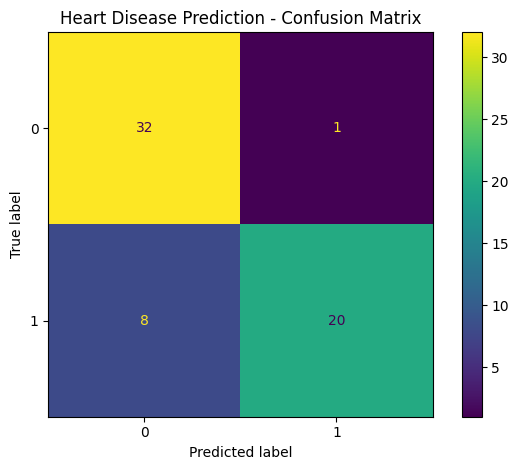

In [21]:

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

# 0 = no disease; 1–4 = disease present
data = df.copy()
data["target"] = (data["target"] > 0).astype(int)

X = data.drop(columns=["target"])
y = data["target"]

print("Target classes:")
print(y.value_counts())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("\nModel Accuracy:",
      round(accuracy_score(y_test, y_pred) * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.title("Heart Disease Prediction - Confusion Matrix")
plt.tight_layout()
plt.show()
